<a href="https://colab.research.google.com/github/nivetithaJ2/Assignment/blob/main/Library_Book_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
data = pd.read_csv('/content/library_data.csv')

print(data.head())


  Student_ID Book_Category Book_Title Borrow_Date Return_Date
0       S101       Science    Physics  01-01-2026  08-01-2026
1       S102       Fiction      Novel  02-01-2026  10-01-2026
2       S103    Technology     Python  03-01-2026  12-01-2026
3       S104       Science  Chemistry  04-01-2026  09-01-2026
4       S105       Fiction      Story  05-01-2026  11-01-2026


In [4]:
print(data.shape)

(55, 5)


In [5]:
print(data.info())

print(data.describe())

print(data.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55 entries, 0 to 54
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Student_ID     55 non-null     object
 1   Book_Category  55 non-null     object
 2   Book_Title     55 non-null     object
 3   Borrow_Date    55 non-null     object
 4   Return_Date    55 non-null     object
dtypes: object(5)
memory usage: 2.3+ KB
None
       Student_ID Book_Category Book_Title Borrow_Date Return_Date
count          55            55         55          55          55
unique         55             5         24          45          50
top          S101       Science    Physics  04-05-2026  22-04-2026
freq            1            18          6           3           2
Student_ID       0
Book_Category    0
Book_Title       0
Borrow_Date      0
Return_Date      0
dtype: int64


In [6]:
data = data.drop_duplicates()

data = data.dropna()

data['Borrow_Date'] = pd.to_datetime(data['Borrow_Date'])

data['Return_Date'] = pd.to_datetime(data['Return_Date'])

print(data.head())

ValueError: time data "23-01-2026" doesn't match format "%m-%d-%Y", at position 6. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [7]:
print(data['Borrow_Date'].head(10))
print(data['Return_Date'].head(10))


0    01-01-2026
1    02-01-2026
2    03-01-2026
3    04-01-2026
4    05-01-2026
5    10-04-2026
6    23-01-2026
7    10-04-2026
8    01-03-2026
9    02-02-2026
Name: Borrow_Date, dtype: object
0    08-01-2026
1    10-01-2026
2    12-01-2026
3    09-01-2026
4    11-01-2026
5    17-04-2026
6    06-02-2026
7    21-04-2026
8    04-03-2026
9    08-02-2026
Name: Return_Date, dtype: object


In [8]:
data = data.drop_duplicates()

data = data.dropna()

data['Borrow_Date'] = pd.to_datetime(
    data['Borrow_Date'],
    format='mixed',
    dayfirst=True
)

data['Return_Date'] = pd.to_datetime(
    data['Return_Date'],
    format='mixed',
    dayfirst=True
)

print(data.head())

  Student_ID Book_Category Book_Title Borrow_Date Return_Date
0       S101       Science    Physics  2026-01-01  2026-01-08
1       S102       Fiction      Novel  2026-01-02  2026-01-10
2       S103    Technology     Python  2026-01-03  2026-01-12
3       S104       Science  Chemistry  2026-01-04  2026-01-09
4       S105       Fiction      Story  2026-01-05  2026-01-11


In [9]:
print(data.dtypes)


Student_ID               object
Book_Category            object
Book_Title               object
Borrow_Date      datetime64[ns]
Return_Date      datetime64[ns]
dtype: object


In [10]:
data['Return_Days'] = (
    data['Return_Date'] - data['Borrow_Date']
).dt.days

print(data['Return_Days'])


0      7
1      8
2      9
3      5
4      6
5      7
6     14
7     11
8      3
9      6
10     6
11    10
12    16
13     9
14     6
15     9
16     8
17     3
18     9
19    16
20     6
21     6
22     6
23    10
24     8
25    14
26     5
27    10
28    13
29     8
30     3
31     4
32    14
33    10
34     7
35    11
36    12
37     6
38     4
39    13
40    12
41    12
42    16
43     4
44    13
45     9
46    14
47     5
48    13
49    12
50    15
51    11
52    10
53     8
54     6
Name: Return_Days, dtype: int64


In [11]:
print("Book Category Count")

print(data['Book_Category'].value_counts())

Book Category Count
Book_Category
Science        18
Fiction        11
Technology     11
Mathematics    10
History         5
Name: count, dtype: int64


In [12]:
print(data['Book_Title'].value_counts())


Book_Title
Physics             6
Statistics          5
Geology             4
Python              4
Story               4
Chemistry           3
Java                3
Short Stories       3
Freedom Struggle    2
Algebra             2
Ecology             2
Astronomy           2
Calculus            2
Modern Era          2
Adventure           2
Novel               1
World History       1
Geometry            1
Data Structures     1
Biology             1
Web Development     1
Fantasy Realm       1
Databases           1
Networking          1
Name: count, dtype: int64


In [13]:
print(data['Return_Days'].mean())

9.054545454545455


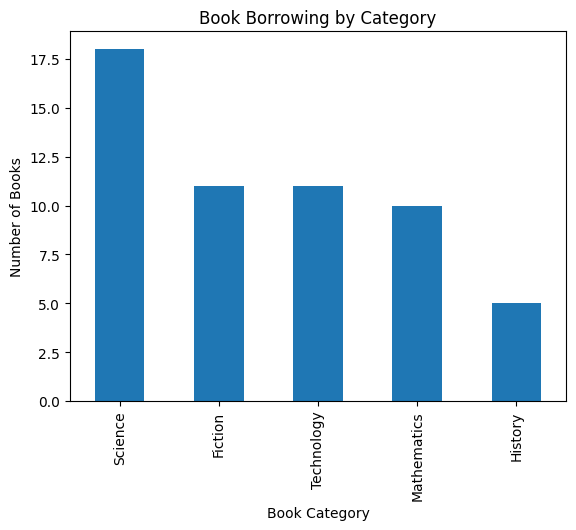

In [14]:
data['Book_Category'].value_counts().plot(kind='bar')

plt.title('Book Borrowing by Category')
plt.xlabel('Book Category')
plt.ylabel('Number of Books')

plt.show()

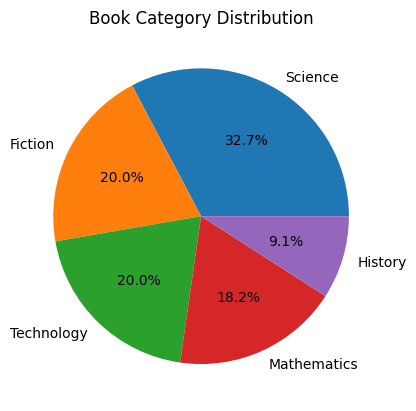

In [15]:
data['Book_Category'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title('Book Category Distribution')
plt.ylabel('')

plt.show()

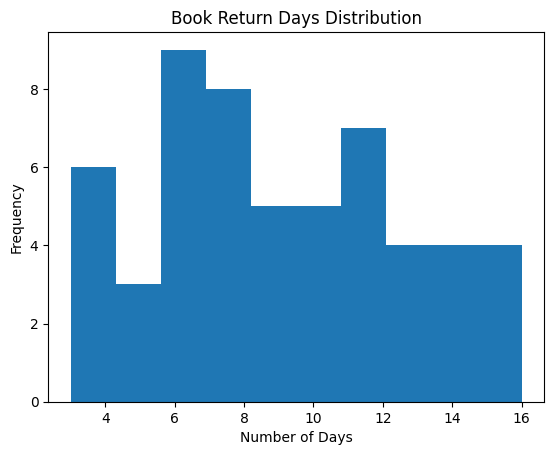

In [16]:
plt.hist(data['Return_Days'], bins=10)

plt.title('Book Return Days Distribution')
plt.xlabel('Number of Days')
plt.ylabel('Frequency')

plt.show()

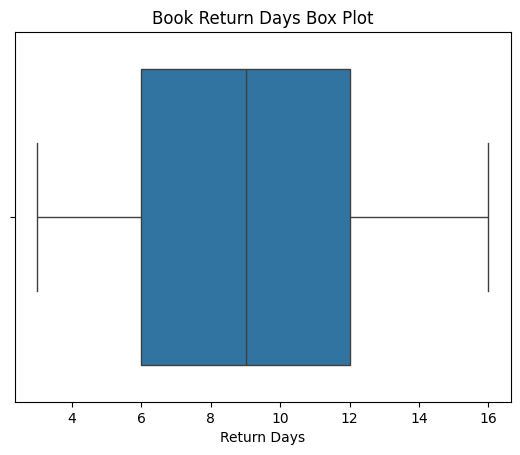

In [17]:
sns.boxplot(x=data['Return_Days'])

plt.title('Book Return Days Box Plot')
plt.xlabel('Return Days')

plt.show()